# RejectLens: a simple reject analysis in digital radiography

**IT6119 Final Project**

This notebook shows how Python can be used to analyse rejected (repeated) X-ray exposures.

All data in this notebook is **synthetic (made up)**. No real patients, staff or hospital data are used.

Run the cells from top to bottom: click a cell and press **Shift + Enter**.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Step 0: Load the tools

These are standard Python libraries. Google Colab already has them installed.

In [3]:
import numpy as np                      # numbers and random values
import pandas as pd                     # tables (like Excel in Python)
import matplotlib.pyplot as plt         # charts
from sklearn.tree import DecisionTreeClassifier, plot_tree   # the simple AI model
from sklearn.model_selection import train_test_split          # split data into train and test
from sklearn.metrics import confusion_matrix                  # count right and wrong answers

print("Tools loaded")

Tools loaded


## Step 1: Make a synthetic reject log

We create 1,000 made-up X-ray exposures. Each row is one exposure with five columns:

| Column | Meaning |
|---|---|
| `exam` | Type of examination |
| `mobility` | How the patient arrived (walking, wheelchair, bed) |
| `shift` | Day, evening or night |
| `rejected` | 1 = image rejected and repeated, 0 = image accepted |
| `reason` | Why the image was rejected (empty if accepted) |

We build in some realistic patterns: bed-bound patients, night shifts and some exams (chest, spine, shoulder) are a bit more likely to be rejected.
The overall reject rate ends up around 9%.

In [4]:
rng = np.random.default_rng(seed=42)    # fixed seed = same "random" data every time
n = 1000                                # number of exposures

# 1. Choose exam, mobility and shift for each exposure
exams    = ["Chest", "Knee", "Wrist/Hand", "Hip/Pelvis", "Lumbar spine", "Shoulder"]
exam     = rng.choice(exams, size=n, p=[0.35, 0.15, 0.15, 0.12, 0.11, 0.12])
mobility = rng.choice(["Walking", "Wheelchair", "Bed"], size=n, p=[0.60, 0.20, 0.20])
shift    = rng.choice(["Day", "Evening", "Night"], size=n, p=[0.60, 0.28, 0.12])

# 2. Give each exposure a chance of being rejected
base_risk = {"Chest": 0.06, "Knee": 0.04, "Wrist/Hand": 0.03,
             "Hip/Pelvis": 0.06, "Lumbar spine": 0.08, "Shoulder": 0.08}
risk = np.array([base_risk[e] for e in exam])
risk = risk + np.where(mobility == "Bed", 0.10, 0) + np.where(mobility == "Wheelchair", 0.03, 0)
risk = risk + np.where(shift == "Night", 0.04, 0)

# 3. Decide if each exposure was rejected (1) or accepted (0)
rejected = (rng.random(n) < risk).astype(int)

# 4. Give rejected images a reason (bed patients move more, so more "Motion")
reasons = ["Positioning", "Motion", "Exposure", "Artefact", "Collimation"]
reason = []
for r, m in zip(rejected, mobility):
    if r == 0:
        reason.append("")
    elif m == "Bed":
        reason.append(rng.choice(reasons, p=[0.40, 0.30, 0.10, 0.10, 0.10]))
    else:
        reason.append(rng.choice(reasons, p=[0.50, 0.12, 0.12, 0.12, 0.14]))

# 5. Put everything into one table
df = pd.DataFrame({"exam": exam, "mobility": mobility, "shift": shift,
                   "rejected": rejected, "reason": reason})

df.to_csv("synthetic_reject_log.csv", index=False)   # save a copy for GitHub
df.head(10)                                          # show the first 10 rows

,exam,mobility,shift,rejected,reason
0,Lumbar spine,Walking,Evening,0,
1,Knee,Walking,Day,0,
2,Lumbar spine,Walking,Night,0,
3,Hip/Pelvis,Walking,Evening,0,
4,Chest,Wheelchair,Day,1,Exposure
5,Shoulder,Walking,Night,0,
6,Hip/Pelvis,Bed,Day,0,
7,Lumbar spine,Walking,Day,0,
8,Chest,Wheelchair,Day,1,Positioning
9,Knee,Walking,Evening,0,


## Step 2: Overall numbers

In [5]:
total    = len(df)
n_reject = df["rejected"].sum()
rate     = n_reject / total * 100

print(f"Total exposures:    {total}")
print(f"Rejected exposures: {n_reject}")
print(f"Reject rate:        {rate:.1f} %")

Total exposures:    1000
Rejected exposures: 93
Reject rate:        9.3 %


## Step 3: Charts

### 3a. Reject rate by exam type

exam
Wrist/Hand       6.2
Knee             6.3
Chest            9.1
Lumbar spine     9.8
Shoulder        12.7
Hip/Pelvis      13.5
Name: rejected, dtype: float64


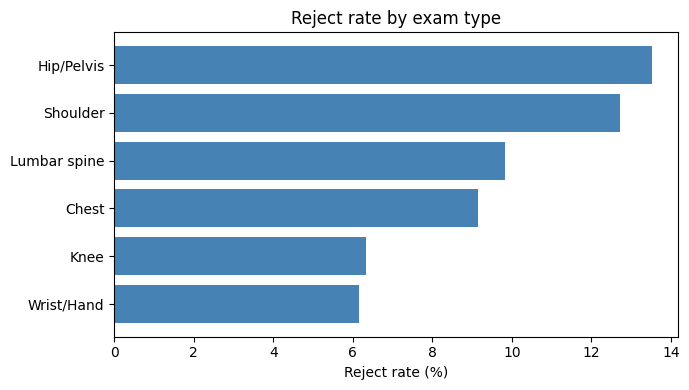

In [6]:
rate_by_exam = df.groupby("exam")["rejected"].mean().sort_values() * 100
print(rate_by_exam.round(1))

plt.figure(figsize=(7, 4))
plt.barh(rate_by_exam.index, rate_by_exam.values, color="steelblue")
plt.xlabel("Reject rate (%)")
plt.title("Reject rate by exam type")
plt.tight_layout()
plt.savefig("fig1_reject_rate_by_exam.png", dpi=200)   # saved for the report
plt.show()

### 3b. Most common reject reasons

reason
Artefact        8
Collimation    10
Exposure       14
Motion         17
Positioning    44
Name: count, dtype: int64


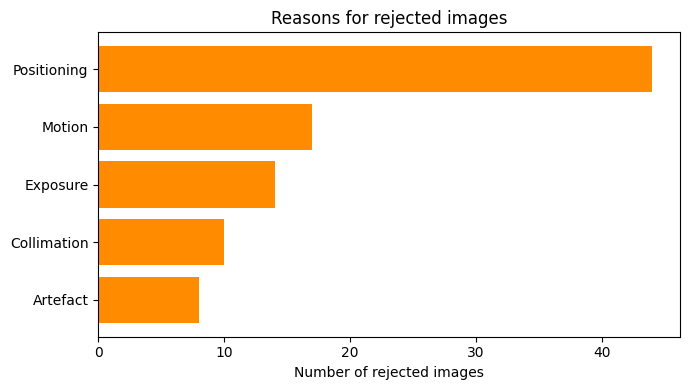

In [7]:
reason_counts = df.loc[df["rejected"] == 1, "reason"].value_counts().sort_values()
print(reason_counts)

plt.figure(figsize=(7, 4))
plt.barh(reason_counts.index, reason_counts.values, color="darkorange")
plt.xlabel("Number of rejected images")
plt.title("Reasons for rejected images")
plt.tight_layout()
plt.savefig("fig2_reject_reasons.png", dpi=200)
plt.show()

### 3c. Reject rate by patient mobility

mobility
Walking        5.1
Wheelchair    11.5
Bed           19.0
Name: rejected, dtype: float64


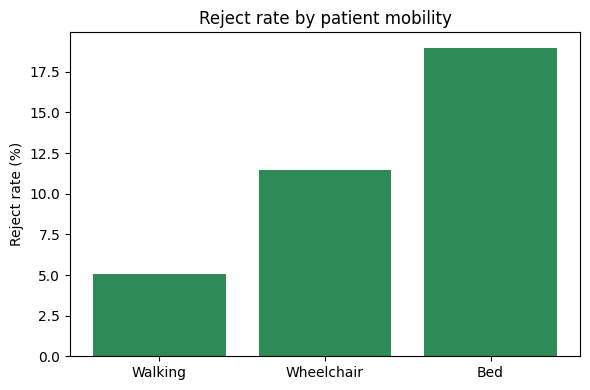

In [8]:
rate_by_mobility = df.groupby("mobility")["rejected"].mean().reindex(["Walking", "Wheelchair", "Bed"]) * 100
print(rate_by_mobility.round(1))

plt.figure(figsize=(6, 4))
plt.bar(rate_by_mobility.index, rate_by_mobility.values, color="seagreen")
plt.ylabel("Reject rate (%)")
plt.title("Reject rate by patient mobility")
plt.tight_layout()
plt.savefig("fig3_reject_rate_by_mobility.png", dpi=200)
plt.show()

## Step 4: A simple AI model (decision tree)

Question: **Can we predict, before the exposure, which exams have a higher risk of being rejected?**

- **Features (inputs):** exam, mobility, shift. These are all known *before* the image is taken.
- **Label (what we predict):** rejected yes/no.
- We do **not** use `reason` as an input. The reason only exists *after* an image is rejected, so using it would be *data leakage* (the model would "see the answer").

We split the data: 70% for training and 30% for testing on exposures the model has never seen.
`class_weight="balanced"` tells the model to take the rare rejected images seriously; otherwise it could simply guess "accepted" every time and still be right 92% of the time.

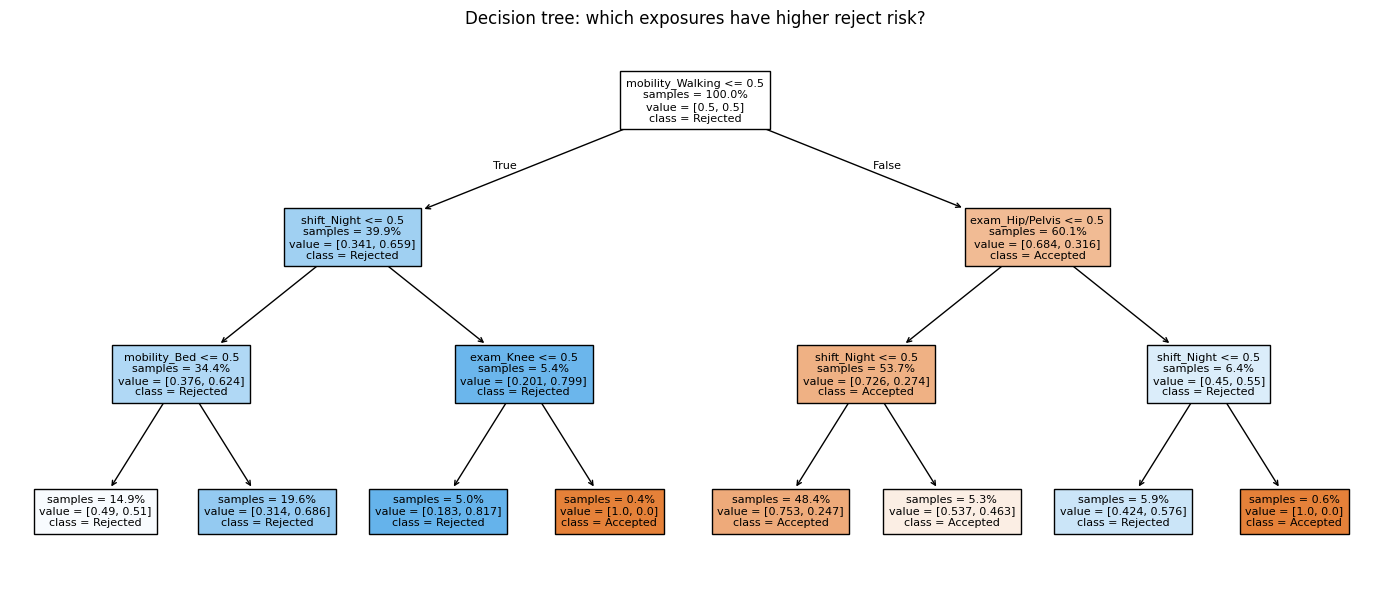

In [9]:
# Inputs: turn text columns into 0/1 columns the model can read
X = pd.get_dummies(df[["exam", "mobility", "shift"]])
y = df["rejected"]

# Split into training data (70%) and test data (30%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

# Train a small decision tree (max 3 questions deep, so it is easy to read)
model = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42)
model.fit(X_train, y_train)

# Draw the tree
plt.figure(figsize=(14, 6))
plot_tree(model, feature_names=X.columns, class_names=["Accepted", "Rejected"],
          filled=True, impurity=False, proportion=True, fontsize=8)
plt.title("Decision tree: which exposures have higher reject risk?")
plt.tight_layout()
plt.savefig("fig4_decision_tree.png", dpi=200)
plt.show()

**How to read the tree:** `mobility_Walking <= 0.5` means "is the patient NOT walking?". *True* goes left, *False* goes right. Blue boxes = the model predicts *Rejected*, orange = *Accepted*. `samples` shows how much of the training data ends up in that box.

## Step 5: How good is the model?

We test the model on the 30% of exposures it has not seen.

- **Sensitivity:** of the images that *were* rejected, how many did the model flag?
- **Specificity:** of the images that were *not* rejected, how many did the model correctly leave unflagged?

In [10]:
y_pred = model.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

print("Confusion matrix (test data):")
print(f"  Correctly flagged (true positive):     {tp}")
print(f"  False alarms (false positive):         {fp}")
print(f"  Missed rejects (false negative):       {fn}")
print(f"  Correctly not flagged (true negative): {tn}")
print()
print(f"Sensitivity: {tp / (tp + fn) * 100:.0f} %")
print(f"Specificity: {tn / (tn + fp) * 100:.0f} %")

Confusion matrix (test data):
  Correctly flagged (true positive):     18
  False alarms (false positive):         130
  Missed rejects (false negative):       10
  Correctly not flagged (true negative): 142

Sensitivity: 64 %
Specificity: 52 %


## Step 6: Conclusion

- Python was used to create a synthetic reject log, calculate the reject rate, make charts and train a simple decision tree.
- In this synthetic data, **positioning** is the most common reject reason, and **bed-bound patients** have the highest reject rate.
- The decision tree finds the same pattern and could, in principle, flag high-risk exams (for example bed-bound patients) so a colleague can help with positioning.
- The model is not very precise: it catches about two out of three rejects, but it also gives many false alarms. This is expected, because most rejects depend on things the model cannot see (for example a patient moving at the wrong moment).
- **Important limitation:** the data is made up, so the model only rediscovers patterns we built in. It is a demonstration of the method, not a tool for clinical use. A real department would need to run the same steps on its own reject log, with permission and proper data protection.